In [4]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [5]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt

from notebooks.imports import *
from src.utils import pmf_utils

In [6]:
from scripts.ucla_rdk import DotMotionStim as RDK_ucla
from scripts.uw_rdk_prelim import RandomDotMotion as RDK_uw

### Config

In [7]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Load and Preprocess data

In [8]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)


# convert pulse info to frame units
convert_to_frame = 1000 / 16.67
data["pulse_onset_frame"] = np.round(data.pulse_onset * convert_to_frame) + 1
data["pulse_offset_frame"] = np.round(data.pulse_onset_frame + (data.pulse_duration * convert_to_frame))
data["rt_frame"] = np.ceil(data.reaction_time * convert_to_frame) + 1

data

,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,stimulus_seed,pulse_type,pulse_onset_frame,pulse_offset_frame,rt_frame
0,0,uw,DBM11,10_1,1,0,False,100,1,1,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.416750,0.066680,-100,612658,-3.0,26.0,30.0,66.0
1,0,uw,DBM11,10_1,2,0,False,100,1,0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.416750,0.066680,100,463182,0.0,26.0,30.0,30.0
2,0,uw,DBM11,10_1,3,0,False,-100,-1,0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.416750,0.066680,100,165712,3.0,26.0,30.0,132.0
3,0,uw,DBM11,10_1,4,0,False,-100,-1,0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.050010,0.066680,-100,418800,-0.0,4.0,8.0,30.0
4,0,uw,DBM11,10_1,5,0,False,-100,-1,0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.233380,0.066680,-100,372882,-0.0,15.0,19.0,60.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,297,ucla,PSUIM9,9_1,346,0,False,18,1,1,1.108688,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.029568,0.050560,100,346,1.0,3.0,6.0,68.0
113870,297,ucla,PSUIM9,9_1,347,0,False,36,1,1,1.598707,1.0,2.6,1.000000,60.0,0.5,0.250000,False,NaN,NaN,0,347,0.0,NaN,NaN,97.0
113871,297,ucla,PSUIM9,9_1,348,0,False,-9,-1,1,2.292042,0.0,0.0,1.000000,60.0,1.5,0.252608,False,NaN,NaN,0,348,0.0,NaN,NaN,139.0
113872,297,ucla,PSUIM9,9_1,349,0,False,36,1,1,1.706793,1.0,2.6,1.000000,60.0,0.5,0.250000,True,0.240538,0.050291,100,349,2.0,15.0,18.0,104.0


### Utils

### Demo

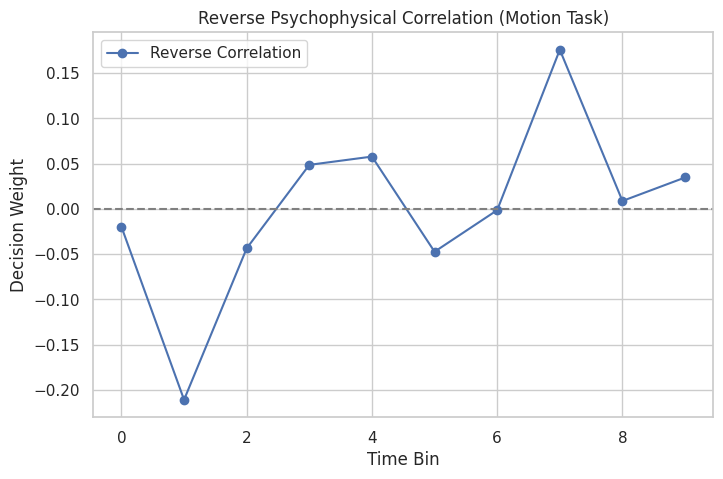

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Simulated dataset: Replace this with real experimental data
num_trials = 1000  # Number of trials
num_time_bins = 10  # Number of time bins per trial

# Generate random dot motion coherence values (-1: leftward, +1: rightward)
motion_energy = np.random.randn(num_trials, num_time_bins)  # Random motion energy per time bin
true_motion = np.sign(np.random.uniform(-1, 1, num_trials))  # True motion direction (-1 or +1)
subject_choices = true_motion * (np.random.rand(num_trials) > 0.3)  # Subject choices with some error

# Normalize motion energy to simulate coherence variation
motion_energy *= np.abs(true_motion[:, None])

# Compute choice-conditioned motion energy
motion_left = motion_energy[subject_choices == -1]
motion_right = motion_energy[subject_choices == 1]

# Compute mean motion energy per time bin for left and right choices
mean_left = np.mean(motion_left, axis=0)
mean_right = np.mean(motion_right, axis=0)

# Compute reverse correlation (difference in motion energy)
reverse_correlation = mean_right - mean_left

# Plot results
plt.figure(figsize=(8, 5))
plt.plot(range(num_time_bins), reverse_correlation, marker="o", linestyle="-", color="b", label="Reverse Correlation")
plt.axhline(0, linestyle="--", color="gray")
plt.xlabel("Time Bin")
plt.ylabel("Decision Weight")
plt.title("Reverse Psychophysical Correlation (Motion Task)")
plt.legend()
plt.show()

### Helper Functions

In [10]:
# calculate motion energy for each trial
def calculate_motion_energy(trial_data, data_source):
    if data_source == "uw":
        _func = None
    elif data_source == "ucla":
        _func = None



In [11]:
rdk_ucla = RDK_ucla()
rdk_uw = RDK_uw()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

import pickle
import numpy as np
import math  # Import the math module for factorial

def f1(x, y, sigma_c=0.35, sigma_g=0.05):
    alpha = np.arctan(x / sigma_c)
    return (np.cos(alpha) ** 4) * (np.cos(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))

def f2(x, y, sigma_c=0.35, sigma_g=0.05):
    alpha = np.arctan(x / sigma_c)
    return (np.cos(alpha) ** 4) * (np.sin(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))

def g1(t):
    return ((60 * t) ** 3) * (np.exp(-60 * t)) * ((1 / math.factorial(3)) - (((60 * t) ** 2) / math.factorial(3 + 2)))

def g2(t):
    return ((60 * t) ** 5) * (np.exp(-60 * t)) * ((1 / math.factorial(5)) - (((60 * t) ** 2) / math.factorial(5 + 2)))

def create_filters(savename="spatiotemporal_filters", nFrames=360):
    # Define space and time values
    x_space = np.arange(-0.7, 0.7, 0.05)
    y_space = np.arange(-0.7, 0.7, 0.05)
    t_space = np.arange(0, 0.2, 0.01)

    # Initialize filters
    Filter_XT_left1 = np.empty((len(t_space), len(x_space), len(y_space)))
    Filter_XT_left2 = np.empty((len(t_space), len(x_space), len(x_space)))
    Filter_XT_right1 = np.empty((len(t_space), len(x_space), len(x_space)))
    Filter_XT_right2 = np.empty((len(t_space), len(x_space), len(x_space)))

    # Create filters by iterating over space and time
    for i, t in enumerate(t_space):
        for j, x in enumerate(x_space):
            Filter_XT_right1[i, j, :] = f1(x, y_space) * g1(t) + f2(x, y_space) * g2(t)
            Filter_XT_right2[i, j, :] = f2(x, y_space) * g1(t) - f1(x, y_space) * g2(t)
            Filter_XT_left1[i, j, :] = f1(x, y_space) * g1(t) - f2(x, y_space) * g2(t)
            Filter_XT_left2[i, j, :] = f2(x, y_space) * g1(t) + f1(x, y_space) * g2(t)

    return Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2


Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2 = create_filters()



def calcualte_motion_energy(data):

    ME_right1 = ndimage.convolve(data, Filter_XT_right1, mode='constant', cval=0.0)
    ME_right2 = ndimage.convolve(data, Filter_XT_right2, mode='constant', cval=0.0)
    ME_left1 = ndimage.convolve(data, Filter_XT_left1, mode='constant', cval=0.0)
    ME_left2 = ndimage.convolve(data, Filter_XT_left2, mode='constant', cval=0.0)

    # Compute the motion energy
    ME_RIGHT = (ME_right1**2) + (ME_right2**2)
    ME_LEFT = (ME_left1**2) + (ME_left2**2)
    ME = ME_RIGHT - ME_LEFT

    return ME

((20, 28, 28), (20, 28, 28), (20, 28, 28), (20, 28, 28))

In [ ]:
def calculate_motion_energy(grayscale_3d_array):
    # Ensure that the number of frames matches
    nFrames = grayscale_3d_array.shape[0]
    # assert nFrames == Filter_XT_right1.shape[0], f"Number of frames ({nFrames}) does not match the filter size ({Filter_XT_right1.shape[0]})"

    # Create an array to store the motion energy for each frame
    ME_T_ms = np.zeros(nFrames)  # Store the motion energy for each frame as a scalar value



    for i in range(nFrames):
        # Get the frame (assumes grayscale_3d_array is 3D: (nFrames, height, width))
        frame = grayscale_3d_array[i]

        # Apply only the 2D slices of the filters for the 2D frame (height x width)
        # Access each filter slice corresponding to the current frame
        ME_right1 = ndimage.convolve(frame, Filter_XT_right1[i, :, :], mode='constant', cval=0.0)
        ME_right2 = ndimage.convolve(frame, Filter_XT_right2[i, :, :], mode='constant', cval=0.0)
        ME_left1 = ndimage.convolve(frame, Filter_XT_left1[i, :, :], mode='constant', cval=0.0)
        ME_left2 = ndimage.convolve(frame, Filter_XT_left2[i, :, :], mode='constant', cval=0.0)

        # Compute the motion energy
        ME_RIGHT = (ME_right1**2) + (ME_right2**2)
        ME_LEFT = (ME_left1**2) + (ME_left2**2)
        ME = ME_RIGHT - ME_LEFT

        # Compute motion energy across the spatial dimensions (mean across height and width)
        ME_XT = np.mean(ME)  # Mean over all pixels (height x width)

        # Store the motion energy for this frame
        ME_T_ms[i] = ME_XT

    return ME_T_ms



In [ ]:
import pygame
import numpy as np

# Initialize Pygame
pygame.init()
screen = pygame.display.set_mode((1280, 720))

# Parameters for stimulus
pulse_onset, pulse_coherence, pulse_offset, signed_coherence = 3, -100, 7, -100
rt_frame = 100
pars = {
    "seed": 0,
    "coherence": 100,
    "pulse": [(pulse_onset, pulse_coherence), (pulse_offset, signed_coherence)],
}


import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

import pickle
import numpy as np
import math  # Import the math module for factorial

def f1(x, y, sigma_c=0.35, sigma_g=0.05):
    alpha = np.arctan(x / sigma_c)
    return (np.cos(alpha) ** 4) * (np.cos(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))

def f2(x, y, sigma_c=0.35, sigma_g=0.05):
    alpha = np.arctan(x / sigma_c)
    return (np.cos(alpha) ** 4) * (np.sin(4 * alpha)) * np.exp((-(y**2)) / (2 * sigma_g**2))

def g1(t):
    return ((60 * t) ** 3) * (np.exp(-60 * t)) * ((1 / math.factorial(3)) - (((60 * t) ** 2) / math.factorial(3 + 2)))

def g2(t):
    return ((60 * t) ** 5) * (np.exp(-60 * t)) * ((1 / math.factorial(5)) - (((60 * t) ** 2) / math.factorial(5 + 2)))

def create_filters(savename="spatiotemporal_filters", nFrames=360):
    # Define space and time values
    x_space = np.arange(-0.7, 0.7, 0.05)
    y_space = np.arange(-0.7, 0.7, 0.05)
    t_space = np.arange(0, 0.2, 0.01)

    # Initialize filters
    Filter_XT_left1 = np.empty((len(t_space), len(x_space), len(y_space)))
    Filter_XT_left2 = np.empty((len(t_space), len(x_space), len(x_space)))
    Filter_XT_right1 = np.empty((len(t_space), len(x_space), len(x_space)))
    Filter_XT_right2 = np.empty((len(t_space), len(x_space), len(x_space)))

    # Create filters by iterating over space and time
    for i, t in enumerate(t_space):
        for j, x in enumerate(x_space):
            Filter_XT_right1[i, j, :] = f1(x, y_space) * g1(t) + f2(x, y_space) * g2(t)
            Filter_XT_right2[i, j, :] = f2(x, y_space) * g1(t) - f1(x, y_space) * g2(t)
            Filter_XT_left1[i, j, :] = f1(x, y_space) * g1(t) - f2(x, y_space) * g2(t)
            Filter_XT_left2[i, j, :] = f2(x, y_space) * g1(t) + f1(x, y_space) * g2(t)

    return Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2


Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2 = create_filters()



def calcualte_motion_energy(data):

    ME_right1 = ndimage.convolve(data, Filter_XT_right1, mode='constant', cval=0.0)
    ME_right2 = ndimage.convolve(data, Filter_XT_right2, mode='constant', cval=0.0)
    ME_left1 = ndimage.convolve(data, Filter_XT_left1, mode='constant', cval=0.0)
    ME_left2 = ndimage.convolve(data, Filter_XT_left2, mode='constant', cval=0.0)

    # Compute the motion energy
    ME_RIGHT = (ME_right1**2) + (ME_right2**2)
    ME_LEFT = (ME_left1**2) + (ME_left2**2)
    ME = ME_RIGHT - ME_LEFT

    return ME


def rgb_to_grayscale(rgb_array):
    """ Convert RGB pixel values to grayscale using luminosity method. """
    grayscale_array = np.dot(rgb_array[...,:3], [0.299, 0.587, 0.114])
    return grayscale_array.astype(np.uint8)

def get_grayscale_frames(rt_frame, pars):
    """ Render frames and return the grayscale pixel values as a 3D NumPy array. """
    frames = []
    rdk_uw.new_stimulus(pars)  # Initialize the stimulus

    for frame_idx in range(rt_frame):
        screen.fill((0, 0, 0))  # Clear screen before drawing

        # Draw dots (your custom drawing code)
        for ind in range(len(rdk_uw.x)):
            pygame.draw.circle(screen, rdk_uw.color, (rdk_uw.x[ind], rdk_uw.y[ind]), rdk_uw.radius)

        pygame.display.update()  # Render frame

        # Convert to grayscale and accumulate frames
        rgb_array = pygame.surfarray.array3d(screen)  # Get RGB values
        grayscale_array = rgb_to_grayscale(rgb_array)
        grayscale_array = np.transpose(grayscale_array)  # Transpose to match (height, width)

        frames.append(grayscale_array)  # Append the grayscale frame to the list

        # Update motion of dots (your custom behavior)
        pulse = pars.get("pulse", ([], []))
        if pulse and frame_idx == pulse[0][0] - 1:
            rdk_uw.move_dots(new_coherence=pulse[0][1])
            pars["pulse"].pop(0)
        else:
            rdk_uw.move_dots()

    # Return all frames as a 3D NumPy array
    return np.array(frames)  # Convert list to 3D NumPy array

# Get the grayscale pixel values (3D NumPy array)
grayscale_3d_array = get_grayscale_frames(rt_frame, pars)

ME_T_ms = calculate_motion_energy(grayscale_3d_array)

# Plot motion energy for visualization
plt.figure(figsize=(10, 5))
plt.plot(ME_T_ms)
plt.title('Motion Energy Time Series')
plt.xlabel('Time (frames)')
plt.ylabel('Motion Energy')
plt.show()


# Print the shape of the 3D array
print("Loaded 3D Array Shape:", grayscale_3d_array.shape)


changing coherence from 100 to -100
changing coherence from -100 to -100


IndexError: index 20 is out of bounds for axis 0 with size 20

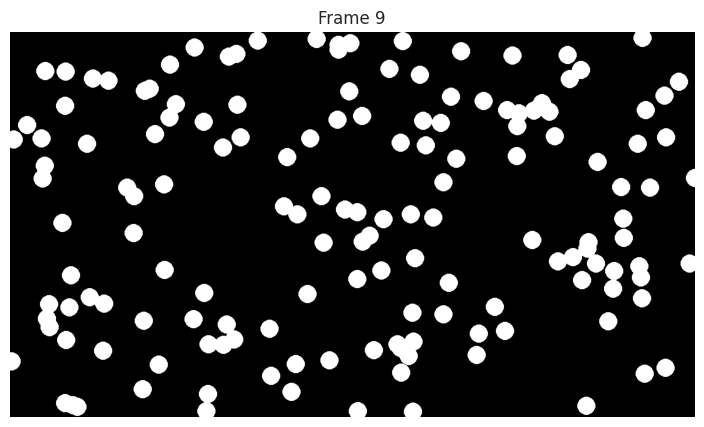

In [66]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
from IPython.display import HTML

# Assuming grayscale_3d_array is already loaded
# Example: shape (10 frames, 720 height, 1280 width)
# grayscale_3d_array = np.random.randint(0, 256, (10, 720, 1280), dtype=np.uint8)

# Initialize the figure and axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')  # Hide axes

# Set up the first frame (to be updated during animation)
im = ax.imshow(grayscale_3d_array[0], cmap='gray')
ax.set_title("Frame 0")

# Function to update each frame in the animation
def update(frame):
    im.set_data(grayscale_3d_array[frame])  # Update the image with the new frame
    ax.set_title(f"Frame {frame}")  # Update the title with the frame number
    return [im]

# Create the animation
ani = FuncAnimation(fig, update, frames=grayscale_3d_array.shape[0], interval=50, blit=True)

# Display the animation in the notebook
HTML(ani.to_jshtml())

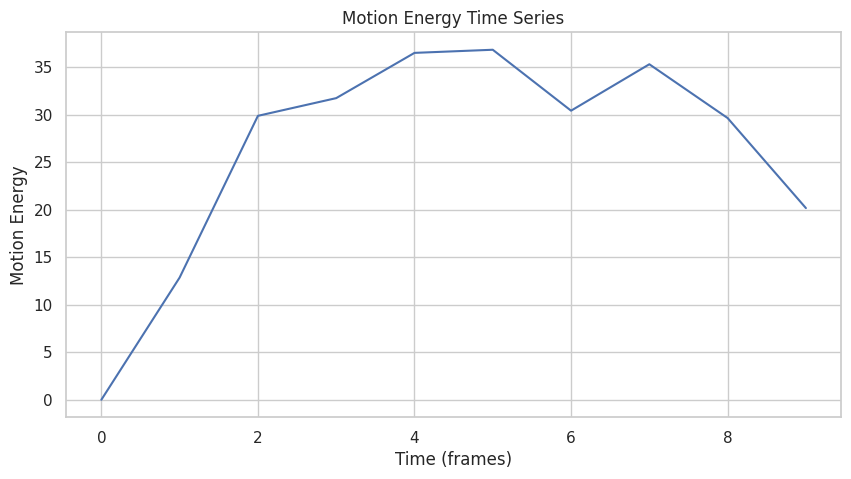

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Assuming create_filters() is already defined to return 3D filters
Filter_XT_right1, Filter_XT_right2, Filter_XT_left1, Filter_XT_left2 = create_filters()

def calculate_motion_energy(grayscale_3d_array):
    # Ensure that the number of frames matches
    nFrames = grayscale_3d_array.shape[0]
    # assert nFrames == Filter_XT_right1.shape[0], f"Number of frames ({nFrames}) does not match the filter size ({Filter_XT_right1.shape[0]})"

    # Create an array to store the motion energy for each frame
    ME_T_ms = np.zeros(nFrames)  # Store the motion energy for each frame as a scalar value

    for i in range(nFrames):
        # Get the frame (assumes grayscale_3d_array is 3D: (nFrames, height, width))
        frame = grayscale_3d_array[i]

        # Apply only the 2D slices of the filters for the 2D frame (height x width)
        # Access each filter slice corresponding to the current frame
        ME_right1 = ndimage.convolve(frame, Filter_XT_right1[i, :, :], mode='constant', cval=0.0)
        ME_right2 = ndimage.convolve(frame, Filter_XT_right2[i, :, :], mode='constant', cval=0.0)
        ME_left1 = ndimage.convolve(frame, Filter_XT_left1[i, :, :], mode='constant', cval=0.0)
        ME_left2 = ndimage.convolve(frame, Filter_XT_left2[i, :, :], mode='constant', cval=0.0)

        # Compute the motion energy
        ME_RIGHT = (ME_right1**2) + (ME_right2**2)
        ME_LEFT = (ME_left1**2) + (ME_left2**2)
        ME = ME_RIGHT - ME_LEFT

        # Compute motion energy across the spatial dimensions (mean across height and width)
        ME_XT = np.mean(ME)  # Mean over all pixels (height x width)

        # Store the motion energy for this frame
        ME_T_ms[i] = ME_XT

    return ME_T_ms

# Example usage
# grayscale_3d_array should be a 3D numpy array with dimensions (nFrames, height, width)
# grayscale_3d_array = np.random.rand(20, 120, 160)  # Replace with your actual grayscale 3D array
grayscale_3d_array.shape
ME_T_ms = calculate_motion_energy(grayscale_3d_array)

# Plot motion energy for visualization
plt.figure(figsize=(10, 5))
plt.plot(ME_T_ms)
plt.title('Motion Energy Time Series')
plt.xlabel('Time (frames)')
plt.ylabel('Motion Energy')
plt.show()

# Optionally, save motion energy to file
# np.savez('motion_energy_data.npz', motion_energy=ME_T_ms)


In [15]:
def generate_pulse_sequence(self):
	pulse_prob = self.pulse_probabilities[self.signed_coherence]
	cumulative_a = np.cumsum(pulse_prob)
	index = np.argmax(cumulative_a >= np.random.uniform())

	if index < 3:
		self.pulse_coherence = -100
	elif index < 6:
		self.pulse_coherence = 100
	else:
		self.pulse_coherence = self.signed_coherence

	if index % 3 == 0:
		self.pulse_onset = self.config.TASK["stimulus"]["pulse_onset"]["value"]["early"]
	elif index % 3 == 1:
		self.pulse_onset = self.config.TASK["stimulus"]["pulse_onset"]["value"]["middle"]
	else:
		self.pulse_onset = self.config.TASK["stimulus"]["pulse_onset"]["value"]["late"]

	pulse = [(int(self.pulse_onset), self.pulse_coherence), (int(self.pulse_onset) + int(self.pulse_duration), self.signed_coherence)]

	return pulse

def initiate_stimulus(self, args):
		self.frame_counter = 0
		args.update(self.initiate_stimulus_config["dots"])
		self.stimulus.new_stimulus(args)

def update_stimulus(self, args=None):
		frame_rate = self.clock.get_fps() or self.frame_rate
		# pulse = [(frame, coherence), (frame, coherence), ...]
		if args and "pulse" in args and args["pulse"]:
			if self.frame_counter == args["pulse"][0][0]:
				self.stimulus.move_dots(frame_rate=frame_rate, new_coherence=args["pulse"][0][1])
				args["pulse"].pop(0)
			else:
				self.stimulus.move_dots(frame_rate=frame_rate)
		else:
			self.stimulus.move_dots(frame_rate=frame_rate)
		self.frame_counter += 1

		func = self.draw_stimulus
		args = {
			"ndots": self.stimulus.nDots,
			"xpos": self.stimulus.x,
			"ypos": self.stimulus.y,
			"radius": [self.stimulus.radius] * self.stimulus.nDots,
			"color": [self.stimulus.color] * self.stimulus.nDots,
		}
		return func, args